In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/insurance.csv")
df.shape
# dataset yuklash va o'chamini ko'rish

(1338, 7)

In [ ]:
df.head()
# dataset boshidan 5 ta qatorni ko'rish

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
df.info()
# dataset ma'lumot turlarini ko'rish

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
df.isnull().sum()
# bo'sh qiymatlar borligini tekshiramiz, lekin bunda yo'q ekan
# ya'ni hamma ma'lumotlar to'liq ekan.

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df.duplicated().sum()
# takrorlangan qiymatlar borligini tekshiramiz, bizga bitta bor ekan

np.int64(1)

In [ ]:
df.describe()
# describe faqat sonli ustunlarni statistilasini hisoblaydi
# by default, df.describe() only calculates statistics for numerical columns.
# It completely ignores string, object, and categorical columns (like addresses, categories, or names)
# if your dataset contains a mix of both types.

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
# category bo'yicha taqsimoti

for col in ['sex', 'smoker', 'region']:
  print(f"\n{col} bo'yicha taqsimot:")
  print(df[col].value_counts())


sex bo'yicha taqsimot:
sex
male      676
female    662
Name: count, dtype: int64

smoker bo'yicha taqsimot:
smoker
no     1064
yes     274
Name: count, dtype: int64

region bo'yicha taqsimot:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


In [ ]:
print(df.groupby('sex')['charges'].agg(['count', 'mean', 'median']))
# jins bo'yicha o'rtacha xarajat hisoblandi.

        count          mean      median
sex                                    
female    662  12569.578844  9412.96250
male      676  13956.751178  9369.61575


In [ ]:
print(df.groupby('smoker')["charges"].agg(['count', 'mean', 'median']))
# chekish bo'yicha o'rtacha xarajat hisoblanadi.

        count          mean       median
smoker                                  
no       1064   8434.268298   7345.40530
yes       274  32050.231832  34456.34845


In [ ]:
print("\n--- Korrelyatsiya (sonli ustunlar) ---")
display(df.select_dtypes(include=[np.number]).corr())


--- Korrelyatsiya (sonli ustunlar) ---


,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


In [ ]:
# 1. Duplicates (Takrorlarni tekshirish va o'chirish)
print("Tozalashdan oldingi shape:", df.shape)
duplicates_count = df.duplicated().sum()
print(f"Takroriy qatorlar soni: {duplicates_count}")

if duplicates_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Takrorlar o'chirildi.")

print("Tozalashdan keyingi shape:", df.shape)

# 2. Outliers tahlili (IQR usuli bilan bmi va charges)
for col in ['bmi', 'charges']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"\n{col} ustunidagi outlierlar soni: {len(outliers)} ({round(len(outliers)/len(df)*100, 2)}%)")
    print(f"Yuqori chegara: {round(upper_bound, 2)}, Maksimal qiymat: {round(df[col].max(), 2)}")

Tozalashdan oldingi shape: (1337, 7)
Takroriy qatorlar soni: 0
Tozalashdan keyingi shape: (1337, 7)

bmi ustunidagi outlierlar soni: 9 (0.67%)
Yuqori chegara: 47.32, Maksimal qiymat: 53.13

charges ustunidagi outlierlar soni: 139 (10.4%)
Yuqori chegara: 34524.78, Maksimal qiymat: 63770.43


In [ ]:
# 1. Semizlik belgisi (BMI >= 30)
df['is_obese'] = (df['bmi'] >= 30).astype(int)

# 2. Bolasi yo'q / yolg'iz belgisi (Titanic'dagi is_alone kabi)
df['is_alone'] = (df['children'] == 0).astype(int)

# 3. Yosh toifalari (age_group)
df['age_group'] = pd.cut(
    df['age'],
    bins=[17, 35, 50, 100],
    labels=['young', 'middle_age', 'senior']
)

# 4. Semiz va chekuvchi (kombinatsiyalangan belgi)
df['obese_smoker'] = ((df['bmi'] >= 30) & (df['smoker'] == 'yes')).astype(int)

# Yangi feature'larning xarajatga ta'sirini tekshiramiz
print("--- Yangi ustunlar bo'yicha charges o'rtachasi ---")
print("\nSemizlik bo'yicha:")
print(df.groupby('is_obese')['charges'].mean().round(2))

print("\nSemiz + Chekuvchi bo'yicha:")
print(df.groupby('obese_smoker')['charges'].mean().round(2))

print("\nYosh toifalari bo'yicha:")
print(df.groupby('age_group', observed=False)['charges'].mean().round(2))

print("\nYangi qatorlar va ustunlar ko'rinishi:")
display(df[['age', 'bmi', 'is_obese', 'is_alone', 'age_group', 'obese_smoker', 'charges']].head())

--- Yangi ustunlar bo'yicha charges o'rtachasi ---

Semizlik bo'yicha:
is_obese
0    10713.67
1    15572.04
Name: charges, dtype: float64

Semiz + Chekuvchi bo'yicha:
obese_smoker
0     9839.16
1    41557.99
Name: charges, dtype: float64

Yosh toifalari bo'yicha:
age_group
young          9758.62
middle_age    14030.00
senior        18084.99
Name: charges, dtype: float64

Yangi qatorlar va ustunlar ko'rinishi:


,age,bmi,is_obese,is_alone,age_group,obese_smoker,charges
0,19,27.900,0,1,young,0,16884.92400
1,18,33.770,1,0,young,0,1725.55230
2,28,33.000,1,0,young,0,4449.46200
3,33,22.705,0,1,young,0,21984.47061
4,32,28.880,0,1,young,0,3866.85520


In [ ]:
from sklearn.preprocessing import LabelEncoder
df_encoded = df.copy()

le = LabelEncoder()
# Binary ustunlar Label encoding ( Sex va Smoker )
df_encoded['sec_encoded'] = le.fit_transform(df_encoded['sex']) # female = 0, male = 1
df_encoded['somker_encoded'] = le.fit_transform(df_encoded['smoker']) # no = 0, yes = 1

# oridinal ustun: age_group(tartibli mapping)
age_map = {'young': 0, 'middle_age': 1, 'senior': 2}
df_encoded['age_group_encoded'] = df_encoded['age_group'].map(age_map)

# Nominal ustun: Region bo'yicha One-Hot Encoding(pf.get_dummies)
region_dummies = pd.get_dummies(df_encoded['region'], prefix='region', dtype=int)
df_encoded = pd.concat([df_encoded, region_dummies], axis=1)

# Asl matnli ustunlarni olib tashlaymiz
cols_to_drop = ['sex', 'smoker', 'region', 'age_group']
df_encoded = df_encoded.drop(columns = cols_to_drop)
print("Encodingdan keyingi untunlar ro'yxati:")
print(df_encoded.columns.tolist())
print('\nBirinchi 3 qator:')
display(df_encoded.head(3))

Encodingdan keyingi untunlar ro'yxati:
['age', 'bmi', 'children', 'charges', 'is_obese', 'is_alone', 'obese_smoker', 'sec_encoded', 'somker_encoded', 'age_group_encoded', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest']

Birinchi 3 qator:


,age,bmi,children,charges,is_obese,is_alone,obese_smoker,sec_encoded,somker_encoded,age_group_encoded,region_northeast,region_northwest,region_southeast,region_southwest
0,19,27.90,0,16884.9240,0,1,0,0,1,0,0,0,0,1
1,18,33.77,1,1725.5523,1,0,0,1,0,0,0,0,1,0
2,28,33.00,3,4449.4620,1,0,0,1,0,0,0,0,1,0


In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

df_scaled = df_encoded.copy()

# Agar imlo xatosi bo'lgan bo'lsa, to'g'rilab olamiz
df_scaled = df_scaled.rename(columns={
    'sec_encoded': 'sex_encoded',
    'somker_encoded': 'smoker_encoded'
})

# 1. MinMax Scaler: age va children uchun
minmax_cols = ['age', 'children']
minmax_scaler = MinMaxScaler()
df_scaled[[c + '_minmax' for c in minmax_cols]] = minmax_scaler.fit_transform(df_scaled[minmax_cols])

# 2. Standard Scaler: bmi uchun (outlierlarga chidamli)
standard_scaler = StandardScaler()
df_scaled['bmi_std'] = standard_scaler.fit_transform(df_scaled[['bmi']])

# Asl o'lchovdagi age, children, bmi ustunlarini saqlash yoki o'chirish
# Modelga faqat masshtablanganlarini kiritish uchun:
features_to_drop = ['age', 'children', 'bmi']
df_scaled_final = df_scaled.drop(columns=features_to_drop)

print("Scaling'dan keyingi ustunlar:")
print(df_scaled_final.columns.tolist())

print("\nMasshtablangan ustunlar statistikasi (describe):")
display(df_scaled_final[['age_minmax', 'children_minmax', 'bmi_std']].describe().round(3))

print("\nBirinchi 3 qator:")
display(df_scaled_final.head(3))

Scaling'dan keyingi ustunlar:
['charges', 'is_obese', 'is_alone', 'obese_smoker', 'sex_encoded', 'smoker_encoded', 'age_group_encoded', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest', 'age_minmax', 'children_minmax', 'bmi_std']

Masshtablangan ustunlar statistikasi (describe):


,age_minmax,children_minmax,bmi_std
count,1337.000,1337.000,1337.000
mean,0.461,0.219,-0.000
std,0.305,0.241,1.000
min,0.000,0.000,-2.411
25%,0.196,0.000,-0.717
50%,0.457,0.200,-0.043
75%,0.717,0.400,0.662
max,1.000,1.000,3.684



Birinchi 3 qator:


,charges,is_obese,is_alone,obese_smoker,sex_encoded,smoker_encoded,age_group_encoded,region_northeast,region_northwest,region_southeast,region_southwest,age_minmax,children_minmax,bmi_std
0,16884.9240,0,1,0,0,1,0,0,0,0,1,0.021739,0.0,-0.453160
1,1725.5523,1,0,0,1,0,0,0,0,1,0,0.000000,0.2,0.509422
2,4449.4620,1,0,0,1,0,0,0,0,1,0,0.217391,0.6,0.383155


In [26]:
# 1. Target ustunni olib tashlab, faqat belgilarni X ga olamiz
X = df_scaled_final.drop(columns=['charges'])

# 2. Faqat charges ustunining o'zini y ga olamiz
y = df_scaled_final['charges']

# O'lchamlarini tekshirib ko'ramiz
print("X shakli (qatorlar, ustunlar):", X.shape)
print("y shakli (qatorlar soni):", y.shape)
print("\nX ning ustunlari:", X.columns.tolist())

X shakli (qatorlar, ustunlar): (1337, 13)
y shakli (qatorlar soni): (1337,)

X ning ustunlari: ['is_obese', 'is_alone', 'obese_smoker', 'sex_encoded', 'smoker_encoded', 'age_group_encoded', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest', 'age_minmax', 'children_minmax', 'bmi_std']


In [27]:
from sklearn.model_selection import train_test_split

# 80% train, 20% test qilib bo'lamiz
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Har bir qismning o'lchamini tekshiramiz
print("O'qitish uchun (X_train):", X_train.shape)
print("Imtihon uchun (X_test):  ", X_test.shape)
print("O'qitish javoblari (y_train):", y_train.shape)
print("Imtihon javoblari (y_test):  ", y_test.shape)

O'qitish uchun (X_train): (1069, 13)
Imtihon uchun (X_test):   (268, 13)
O'qitish javoblari (y_train): (1069,)
Imtihon javoblari (y_test):   (268,)


In [28]:
from sklearn.linear_model import LinearRegression

# 1. Model obyektini yaratamiz
model = LinearRegression()

# 2. Modelni X_train va y_train ustida o'qitamiz
model.fit(X_train, y_train)

print("Model muvaffaqiyatli o'qitildi!")

Model muvaffaqiyatli o'qitildi!


In [29]:
# 1. Test to'plami bo'yicha bashorat qilamiz
y_pred = model.predict(X_test)

# 2. Haqiqiy va bashorat qilingan narxlarni taqqoslash uchun jadval yasaymiz
comparison_df = pd.DataFrame({
    'Haqiqiy narx (Real)': y_test.values,
    'Model bashorati (Pred)': y_pred,
    'Farq (Xato)': np.abs(y_test.values - y_pred)
}).round(2)

print("Dastlabki 5 ta bemor uchun natijalar:")
display(comparison_df.head())

Dastlabki 5 ta bemor uchun natijalar:


,Haqiqiy narx (Real),Model bashorati (Pred),Farq (Xato)
0,8688.86,9868.34,1179.48
1,5708.87,6628.62,919.75
2,11436.74,13721.67,2284.93
3,38746.36,40078.35,1332.00
4,4463.21,6609.89,2146.69


In [30]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# Metrikalarni hisoblaymiz
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

print("--- Test to'plami bo'yicha baholash ---")
print(f"R² score : {r2:.4f}  (Model aniqligi: {r2*100:.2f}%)")
print(f"MAE      : ${mae:,.2f}  (O'rtacha adashish)")
print(f"RMSE     : ${rmse:,.2f}")
print(f"MAPE     : {mape:.2f}%  (Foizdagi o'rtacha xato)")

--- Test to'plami bo'yicha baholash ---
R² score : 0.9064  (Model aniqligi: 90.64%)
MAE      : $2,371.17  (O'rtacha adashish)
RMSE     : $4,147.89
MAPE     : 26.32%  (Foizdagi o'rtacha xato)


In [33]:
# 1. Model o'rgangan har bir ustun og'irligini jadvalga yig'amiz
coef_df = pd.DataFrame({
    'Belgi (Feature)': X.columns,
    'Ta\'sir kuchi ($)': model.coef_
})

# 2. Eng kuchli ta'sir qiluvchilarni tepaga chiqarish (absolyut qiymat bo'yicha saralash)
coef_df['Abs_Val'] = coef_df['Ta\'sir kuchi ($)'].abs()
coef_df = coef_df.sort_values(by='Abs_Val', ascending=False).drop(columns=['Abs_Val']).reset_index(drop=True)

print("--- Har bir belgining narxga ta'siri ---")
display(coef_df)

print(f"\nBoshlang'ich baza narx (Intercept / b): ${model.intercept_:,.2f}")

--- Har bir belgining narxga ta'siri ---


,Belgi (Feature),Ta'sir kuchi ($)
0,obese_smoker,19578.906649
1,smoker_encoded,13241.078425
2,age_minmax,10115.289606
3,children_minmax,2577.855617
4,age_group_encoded,715.310431
5,region_southwest,-648.763921
6,sex_encoded,-478.776584
7,bmi_std,476.709003
8,is_obese,-470.606182
9,region_northeast,456.329992



Boshlang'ich baza narx (Intercept / b): $3,192.04


/tmp/ipykernel_2050/1588336580.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


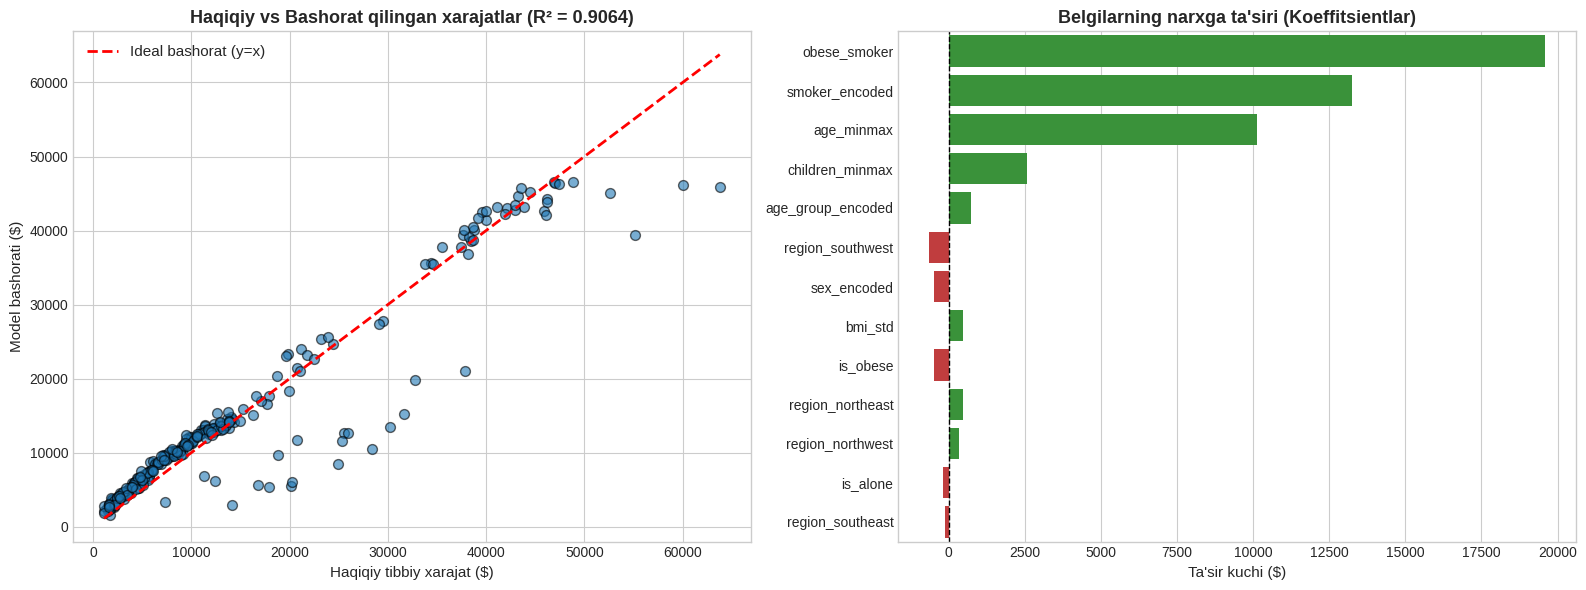

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafiklar uslubini sozlaymiz
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1-GRAFIK: Haqiqiy narxlar va Model bashoratlari
axes[0].scatter(y_test, y_pred, alpha=0.6, color='#1f77b4', edgecolors='k', s=50)
# Ideal to'g'ri chiziq (haqiqiy narx = bashorat)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal bashorat (y=x)')

axes[0].set_title(f"Haqiqiy vs Bashorat qilingan xarajatlar (R² = {r2:.4f})", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Haqiqiy tibbiy xarajat ($)", fontsize=11)
axes[0].set_ylabel("Model bashorati ($)", fontsize=11)
axes[0].legend(fontsize=11)

# 2-GRAFIK: Belgilarning ta'siri (Feature Importance / Coefficients)
colors = ['#d62728' if x < 0 else '#2ca02c' for x in coef_df['Ta\'sir kuchi ($)']]
sns.barplot(
    data=coef_df,
    x='Ta\'sir kuchi ($)',
    y='Belgi (Feature)',
    palette=colors,
    ax=axes[1]
)
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title("Belgilarning narxga ta'siri (Koeffitsientlar)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Ta'sir kuchi ($)", fontsize=11)
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()